In [45]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [46]:
df_mapping = pd.read_csv('tennet_series_mapping.csv')
df = pd.read_csv('tennet_hourly_2015-01-01_2022-12-31.csv')
df

,datetime_utc,datetime_berlin,1223_TenneT,4069_TenneT,4071_TenneT,1227_TenneT,1224_TenneT,4067_TenneT,1225_TenneT,4068_TenneT,1226_TenneT,4070_TenneT,4066_TenneT,1228_TenneT,410_TenneT,4359_TenneT,4387_TenneT
0,2014-12-31 23:00:00+0000,2015-01-01 00:00:00+0100,368.00,1026.75,714.0,20.0,4860.50,3591.50,468.50,0.00,545.25,566.75,2097.75,19.00,14110.25,10050.25,66.50
1,2015-01-01 00:00:00+0000,2015-01-01 01:00:00+0100,313.75,941.25,466.0,20.0,5278.75,3415.25,468.25,0.00,587.75,126.25,2094.75,19.00,13267.50,9384.00,9.25
2,2015-01-01 01:00:00+0000,2015-01-01 02:00:00+0100,254.25,937.00,406.5,20.0,5227.25,3507.50,466.00,0.00,536.75,36.50,2097.00,19.00,12642.00,8668.50,85.50
3,2015-01-01 02:00:00+0000,2015-01-01 03:00:00+0100,251.50,913.75,416.5,20.0,5234.50,3724.00,470.00,0.00,518.00,0.00,2098.50,19.50,12132.50,7938.50,653.50
4,2015-01-01 03:00:00+0000,2015-01-01 04:00:00+0100,243.75,937.25,425.5,20.0,5155.75,3972.75,473.25,0.00,509.00,0.00,2093.50,19.50,11840.25,7394.25,1226.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70123,2022-12-31 18:00:00+0000,2022-12-31 19:00:00+0100,5.00,375.00,410.0,269.0,1368.25,11537.75,3467.50,3.00,423.75,467.00,2164.25,31.00,15133.50,125.25,129.00
70124,2022-12-31 19:00:00+0000,2022-12-31 20:00:00+0100,5.00,373.00,409.0,269.0,1370.75,11801.00,3301.75,3.25,433.00,322.50,2064.75,31.00,14012.25,-1093.75,70.50
70125,2022-12-31 20:00:00+0000,2022-12-31 21:00:00+0100,9.00,373.75,409.0,275.0,1371.50,12231.00,3181.25,3.25,417.25,355.00,1974.25,30.25,13215.25,-2200.25,46.50
70126,2022-12-31 21:00:00+0000,2022-12-31 22:00:00+0100,5.00,375.50,408.0,270.0,1372.75,12283.75,3180.75,3.25,423.25,288.25,1937.25,31.00,12973.75,-2494.00,23.25


In [47]:
df_mapping

,col_id,deutscher_name,english_name,unit
0,1223,Braunkohle,Lignite,MWh
1,4069,Steinkohle,Hard coal,MWh
2,4071,Erdgas,Natural gas,MWh
3,1227,Sonstige konventionelle Energieträger,Other conventional energy sources,MWh
4,1224,Kernenergie,Nuclear,MWh
5,4067,Wind Onshore,Onshore wind,MWh
6,1225,Wind Offshore,Offshore wind,MWh
7,4068,Photovoltaik,Photovoltaics,MWh
8,1226,Wasserkraft,Hydropower,MWh
9,4070,Pumpspeicher (Erzeugung),Pumped storage generation,MWh


In [48]:
# 1. 构造映射字典 {代码: 名称}
mapping_dict = df_mapping.set_index('col_id')['english_name'].to_dict()

# 2. 遍历列名，动态切片到 '_' 字符
new_columns = []
for col in df.columns:
    # 确保 col 是字符串类型再处理
    if not isinstance(col, str):
        new_columns.append(col)
        continue
        
    # 如果列名中包含 '_'
    if '_' in col:
        # split('_', 1) 会将字符串以第一个 '_' 为界，切分成两部分
        prefix, suffix = col.split('_', 1)
        suffix = '_' + suffix  # 把下划线补回给后缀 (例如 '_SZ')
        
        # 尝试转为 int 进行字典匹配（如果字典 key 是字符串，把 int() 去掉即可）
        if prefix.isdigit():
            int_prefix = int(prefix)
            if int_prefix in mapping_dict:
                new_columns.append(f"{mapping_dict[int_prefix]}")
                continue
        elif prefix in mapping_dict:  # 如果字典 key 本来就是字符串
            new_columns.append(f"{mapping_dict[prefix]}{suffix}")
            continue

    # 如果没匹配到，或者列名里没有 '_'，保持原样
    new_columns.append(col)

# 3. 重新赋值列名
df.columns = new_columns
df

,datetime_utc,datetime_berlin,Lignite,Hard coal,Natural gas,Other conventional energy sources,Nuclear,Onshore wind,Offshore wind,Photovoltaics,Hydropower,Pumped storage generation,Biomass,Other renewables,Total load,Residual load,Pumped storage consumption
0,2014-12-31 23:00:00+0000,2015-01-01 00:00:00+0100,368.00,1026.75,714.0,20.0,4860.50,3591.50,468.50,0.00,545.25,566.75,2097.75,19.00,14110.25,10050.25,66.50
1,2015-01-01 00:00:00+0000,2015-01-01 01:00:00+0100,313.75,941.25,466.0,20.0,5278.75,3415.25,468.25,0.00,587.75,126.25,2094.75,19.00,13267.50,9384.00,9.25
2,2015-01-01 01:00:00+0000,2015-01-01 02:00:00+0100,254.25,937.00,406.5,20.0,5227.25,3507.50,466.00,0.00,536.75,36.50,2097.00,19.00,12642.00,8668.50,85.50
3,2015-01-01 02:00:00+0000,2015-01-01 03:00:00+0100,251.50,913.75,416.5,20.0,5234.50,3724.00,470.00,0.00,518.00,0.00,2098.50,19.50,12132.50,7938.50,653.50
4,2015-01-01 03:00:00+0000,2015-01-01 04:00:00+0100,243.75,937.25,425.5,20.0,5155.75,3972.75,473.25,0.00,509.00,0.00,2093.50,19.50,11840.25,7394.25,1226.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70123,2022-12-31 18:00:00+0000,2022-12-31 19:00:00+0100,5.00,375.00,410.0,269.0,1368.25,11537.75,3467.50,3.00,423.75,467.00,2164.25,31.00,15133.50,125.25,129.00
70124,2022-12-31 19:00:00+0000,2022-12-31 20:00:00+0100,5.00,373.00,409.0,269.0,1370.75,11801.00,3301.75,3.25,433.00,322.50,2064.75,31.00,14012.25,-1093.75,70.50
70125,2022-12-31 20:00:00+0000,2022-12-31 21:00:00+0100,9.00,373.75,409.0,275.0,1371.50,12231.00,3181.25,3.25,417.25,355.00,1974.25,30.25,13215.25,-2200.25,46.50
70126,2022-12-31 21:00:00+0000,2022-12-31 22:00:00+0100,5.00,375.50,408.0,270.0,1372.75,12283.75,3180.75,3.25,423.25,288.25,1937.25,31.00,12973.75,-2494.00,23.25


In [49]:
df.columns

Index(['datetime_utc', 'datetime_berlin', 'Lignite', 'Hard coal',
       'Natural gas', 'Other conventional energy sources', 'Nuclear',
       'Onshore wind', 'Offshore wind', 'Photovoltaics', 'Hydropower',
       'Pumped storage generation', 'Biomass', 'Other renewables',
       'Total load', 'Residual load', 'Pumped storage consumption'],
      dtype='object')

In [50]:
import pandas as pd

# 1. Set the time column as the index (choose 'datetime_utc' or 'datetime_berlin')
df_time = df.set_index('datetime_utc')

# 2. Define the category mapping dictionary
category_map = {
    # Thermal Category
    'Lignite': 'Thermal',
    'Hard coal': 'Thermal',
    'Natural gas': 'Thermal',
    'Biomass': 'Thermal',
    'Other conventional energy sources': 'Thermal',
    
    # Water Category
    'Hydropower': 'Water',
    'Pumped storage generation': 'Water',
    
    # Wind Category
    'Onshore wind': 'Wind',
    'Offshore wind': 'Wind',
    
    # Nuclear Category
    'Nuclear': 'Nuclear',
    
    # Solar Category (Optional: separated or added to renewables)
    'Photovoltaics': 'Solar',
    'Other renewables': 'Other Renewables'
}

# 3. Filter to keep only the energy generation columns defined in the map
valid_cols = [col for col in df_time.columns if col in category_map]
df_filtered = df_time[valid_cols]

# 4. Group by columns (axis=1) using the map and sum the values
df_ts_categories = df_filtered.groupby(category_map, axis=1).sum()

# 5. Bring the datetime back as a column if you prefer it as data rather than index
df_ts_categories = df_ts_categories.reset_index()
df_ts_categories

,datetime_utc,Nuclear,Other Renewables,Solar,Thermal,Water,Wind
0,2014-12-31 23:00:00+0000,4860.50,19.00,0.00,4226.50,1112.00,4060.00
1,2015-01-01 00:00:00+0000,5278.75,19.00,0.00,3835.75,714.00,3883.50
2,2015-01-01 01:00:00+0000,5227.25,19.00,0.00,3714.75,573.25,3973.50
3,2015-01-01 02:00:00+0000,5234.50,19.50,0.00,3700.25,518.00,4194.00
4,2015-01-01 03:00:00+0000,5155.75,19.50,0.00,3720.00,509.00,4446.00
...,...,...,...,...,...,...,...
70123,2022-12-31 18:00:00+0000,1368.25,31.00,3.00,3223.25,890.75,15005.25
70124,2022-12-31 19:00:00+0000,1370.75,31.00,3.25,3120.75,755.50,15102.75
70125,2022-12-31 20:00:00+0000,1371.50,30.25,3.25,3041.00,772.25,15412.25
70126,2022-12-31 21:00:00+0000,1372.75,31.00,3.25,2995.75,711.50,15464.50


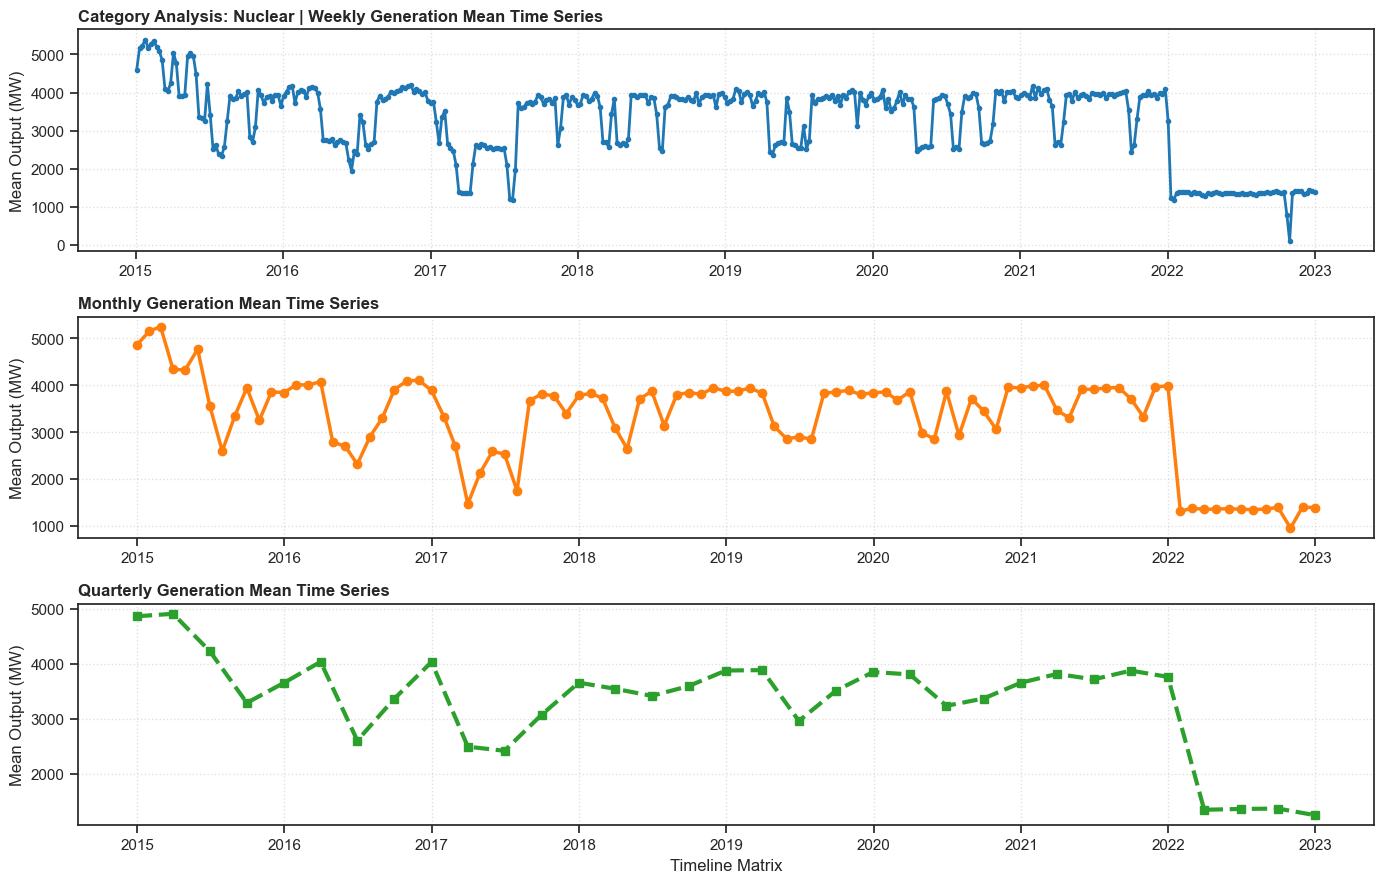

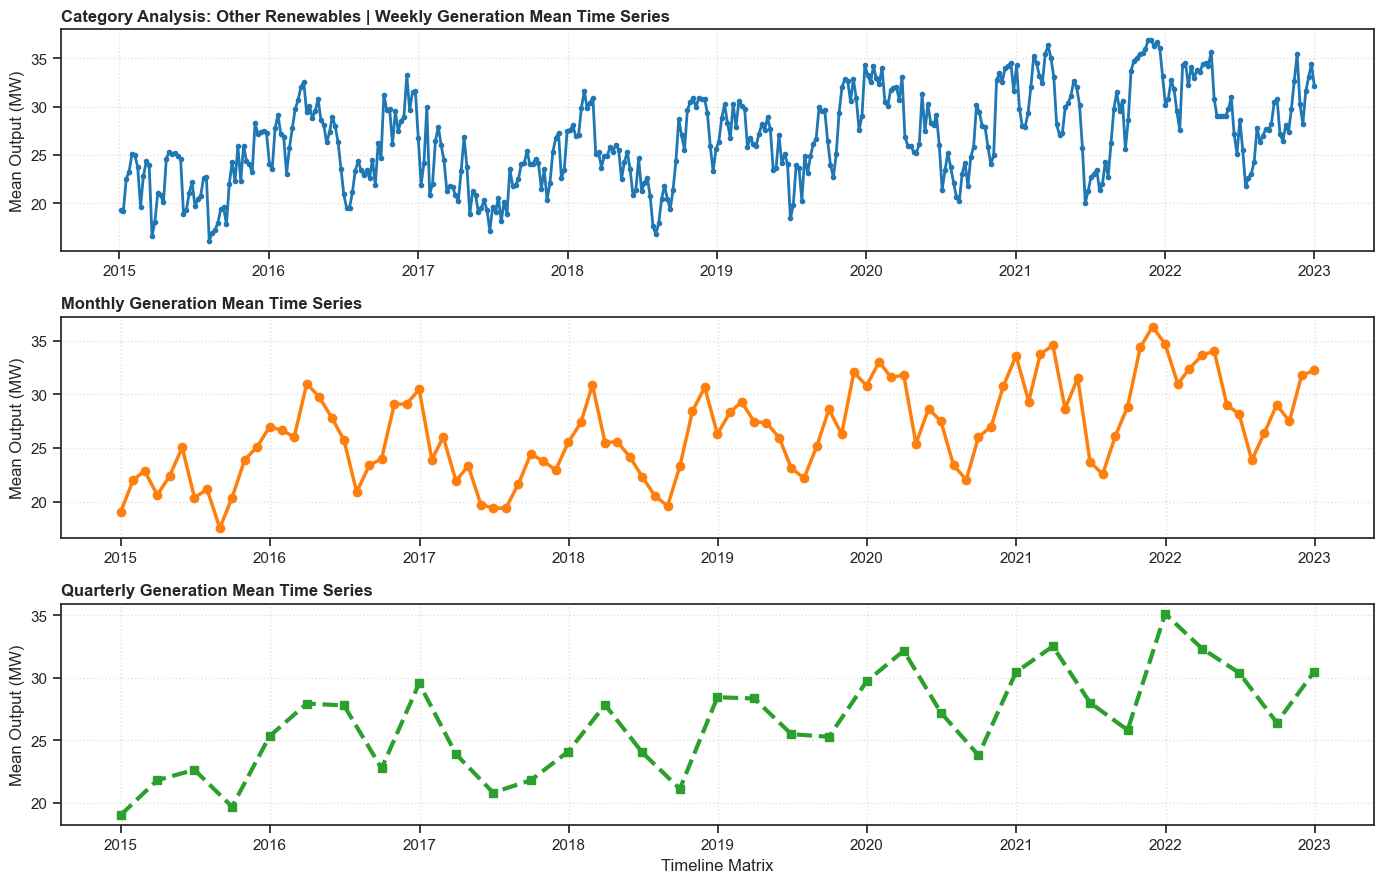

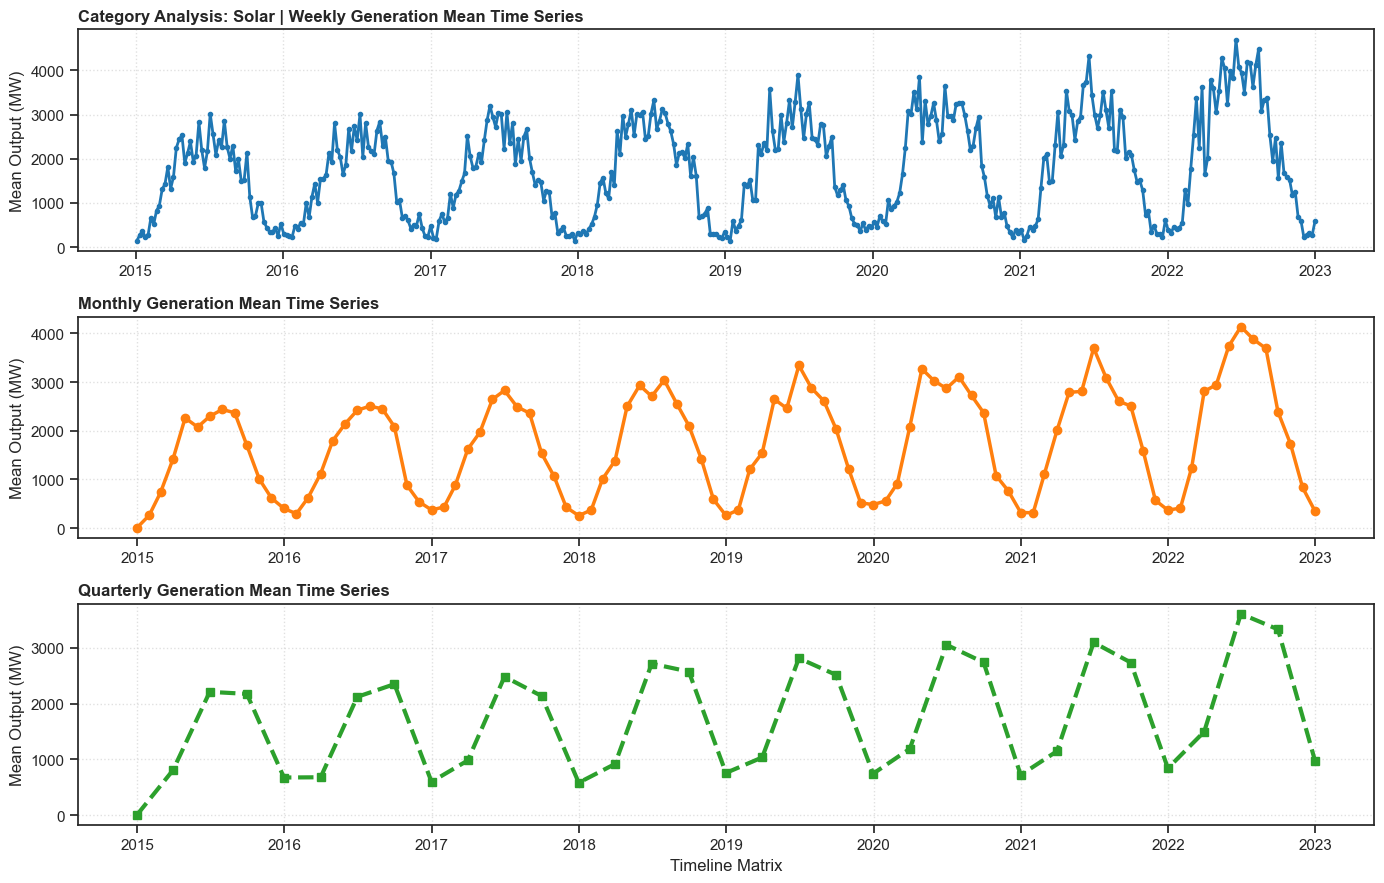

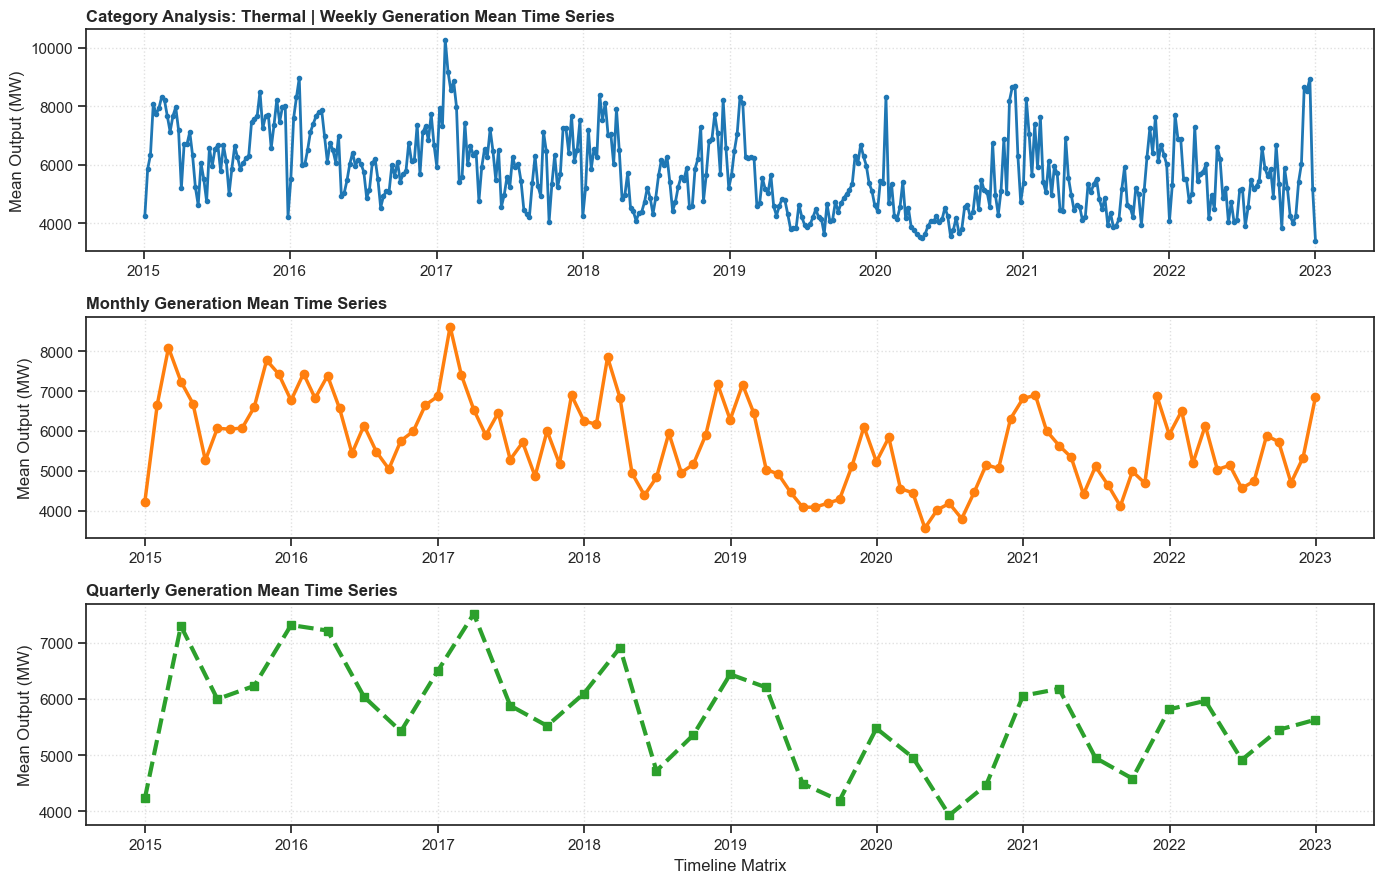

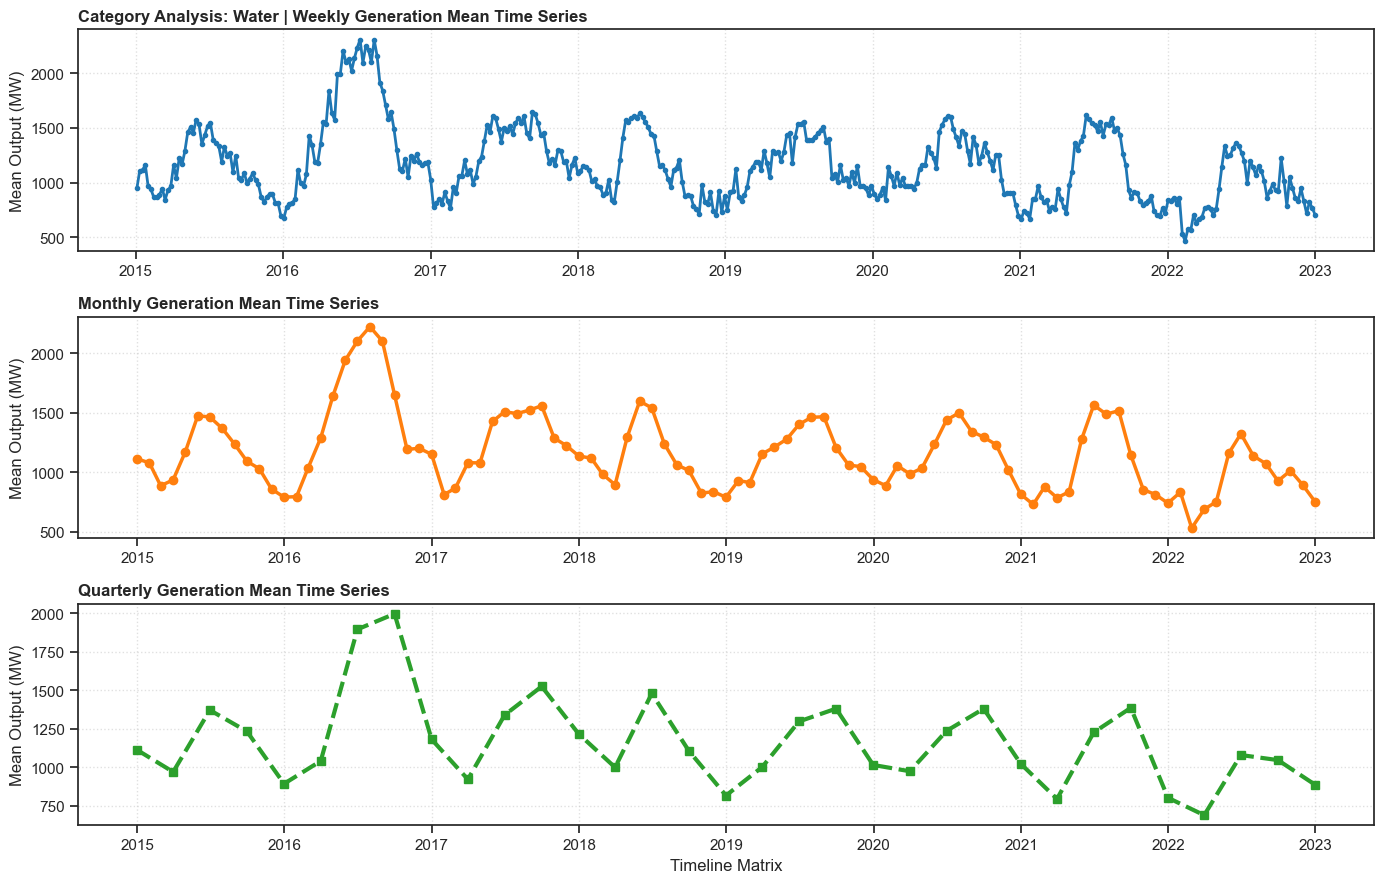

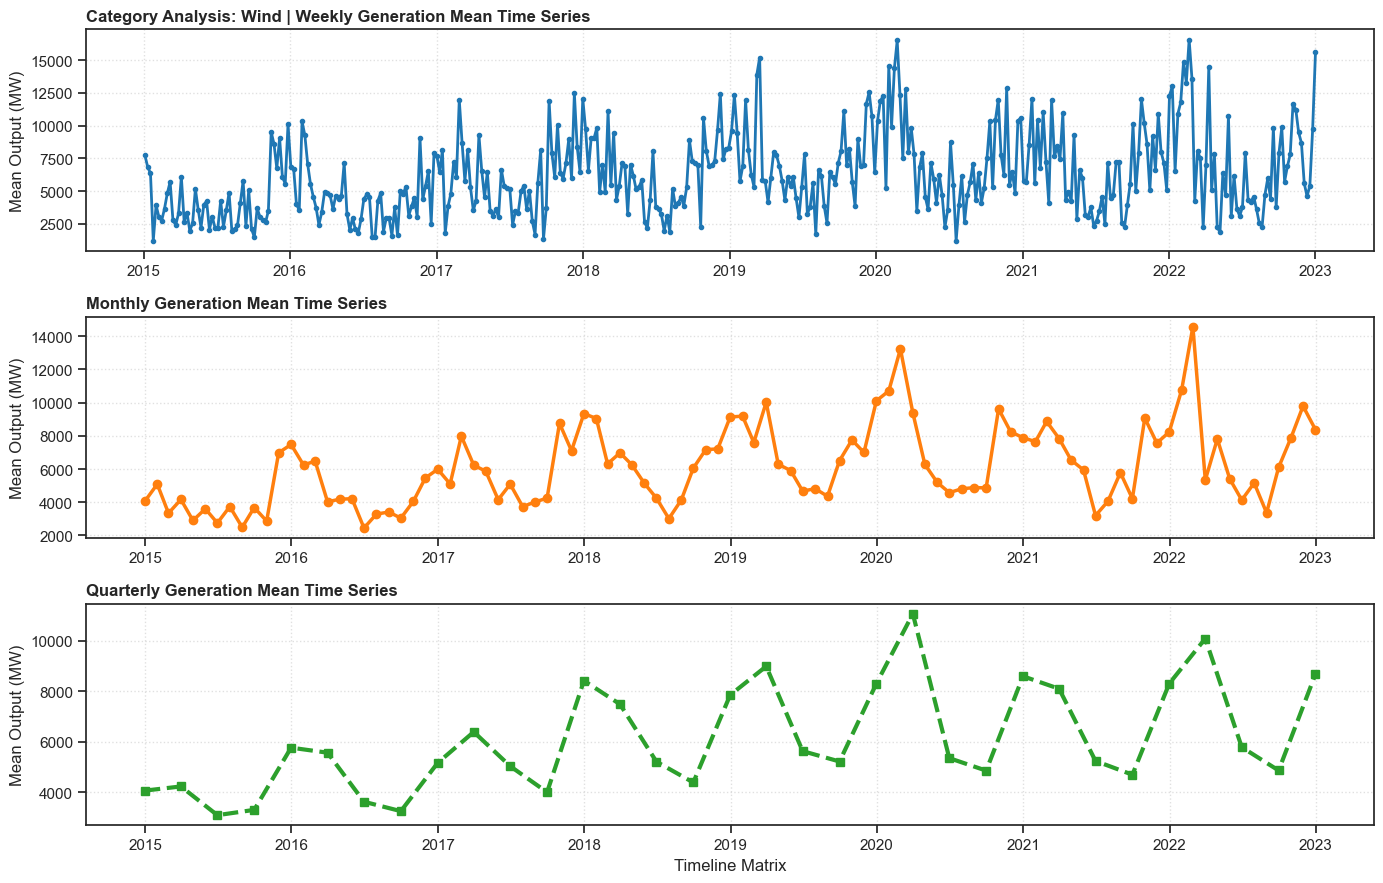

In [51]:
# ==============================================================================
# 0. DATETIME ALIGNMENT
# ==============================================================================
df_analysis = df_ts_categories.copy()

if "datetime_utc" in df_analysis.columns:
    df_analysis["datetime_utc"] = pd.to_datetime(df_analysis["datetime_utc"])
    df_analysis = df_analysis.set_index("datetime_utc")
else:
    df_analysis.index = pd.to_datetime(df_analysis.index)

energy_cols = [
    c
    for c in df_analysis.columns
    if c not in ["Hour", "Month", "Season", "Year", "DayOfWeek"]
]

sns.set_theme(style="ticks", context="notebook")

# ==============================================================================
# 1. COMPUTING PERIODIC MEANS (Compatible legacy offsets 'W', 'M', 'Q')
# ==============================================================================
df_weekly_mean = df_analysis[energy_cols].resample("W").mean()
df_monthly_mean = df_analysis[energy_cols].resample("M").mean()
df_quarterly_mean = df_analysis[energy_cols].resample("Q").mean()

# ==============================================================================
# 2. VISUALIZATION: SEPARATE FREQUENCY GRAPH SUITES
# ==============================================================================
# This loop generates a dedicated 3-panel stacked subplot layout for EACH category
for col in energy_cols:
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=False)

    # Panel A: Weekly Cycle Trends
    axes[0].plot(
        df_weekly_mean.index,
        df_weekly_mean[col],
        color ="#1f77b4",
        linewidth=2,
        marker=".",
    )
    axes[0].set_title(
        f"Category Analysis: {col} | Weekly Generation Mean Time Series",
        weight="bold",
        loc="left",
    )
    axes[0].set_ylabel("Mean Output (MW)")
    axes[0].grid(True, linestyle=":", alpha=0.6)

    # Panel B: Month-Over-Month Macro Volatility
    axes[1].plot(
        df_monthly_mean.index,
        df_monthly_mean[col],
        color="#ff7f0e",
        linewidth=2.5,
        marker="o",
    )
    axes[1].set_title(
        f"Monthly Generation Mean Time Series", weight="bold", loc="left"
    )
    axes[1].set_ylabel("Mean Output (MW)")
    axes[1].grid(True, linestyle=":", alpha=0.6)

    # Panel C: Long-Term Deep Quarterly Trends
    axes[2].plot(
        df_quarterly_mean.index,
        df_quarterly_mean[col],
        color="#2ca02c",
        linewidth=3,
        marker="s",
        linestyle="--",
    )
    axes[2].set_title(
        f"Quarterly Generation Mean Time Series", weight="bold", loc="left"
    )
    axes[2].set_ylabel("Mean Output (MW)")
    axes[2].set_xlabel("Timeline Matrix")
    axes[2].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

In [56]:
df_analysis

,Nuclear,Other Renewables,Solar,Thermal,Water,Wind
datetime_utc,,,,,,
2014-12-31 23:00:00+00:00,4860.50,19.00,0.00,4226.50,1112.00,4060.00
2015-01-01 00:00:00+00:00,5278.75,19.00,0.00,3835.75,714.00,3883.50
2015-01-01 01:00:00+00:00,5227.25,19.00,0.00,3714.75,573.25,3973.50
2015-01-01 02:00:00+00:00,5234.50,19.50,0.00,3700.25,518.00,4194.00
2015-01-01 03:00:00+00:00,5155.75,19.50,0.00,3720.00,509.00,4446.00
...,...,...,...,...,...,...
2022-12-31 18:00:00+00:00,1368.25,31.00,3.00,3223.25,890.75,15005.25
2022-12-31 19:00:00+00:00,1370.75,31.00,3.25,3120.75,755.50,15102.75
2022-12-31 20:00:00+00:00,1371.50,30.25,3.25,3041.00,772.25,15412.25


In [57]:
category_cols = [
    'Thermal',
    'Water',
    'Wind',
    'Nuclear',
    'Solar',
    'Other Renewables'
]

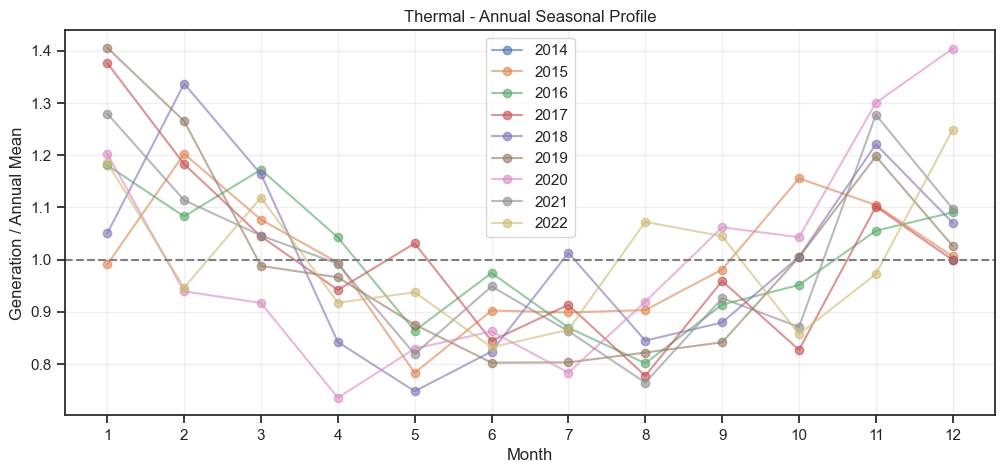

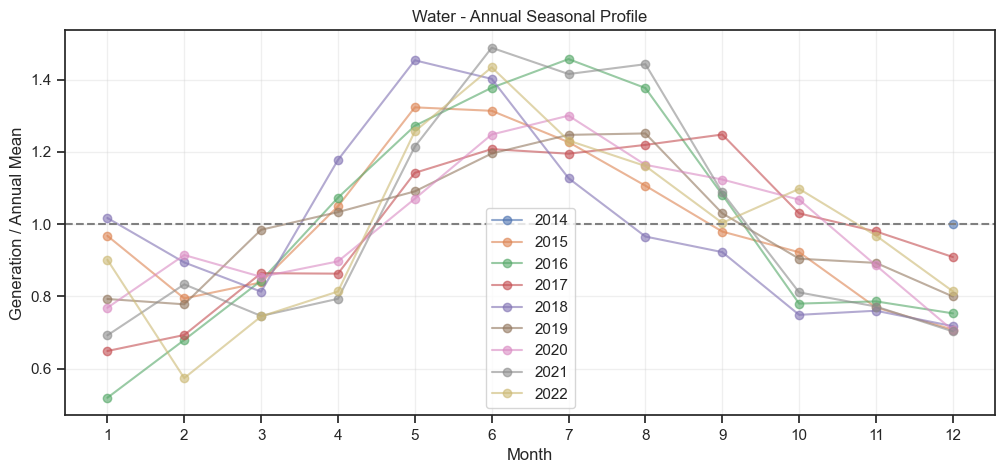

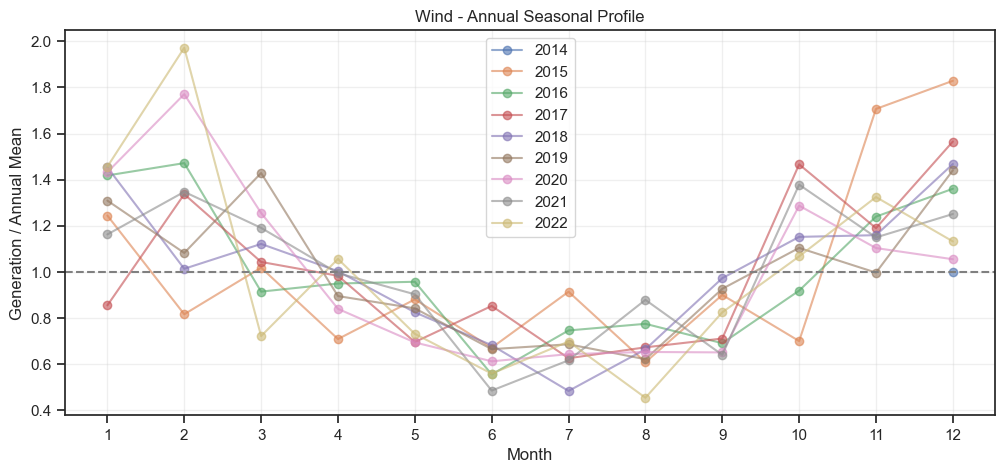

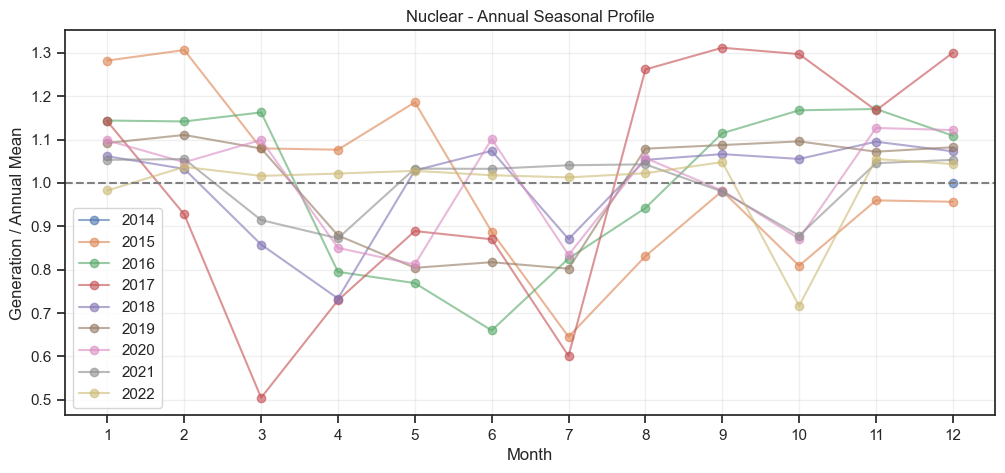

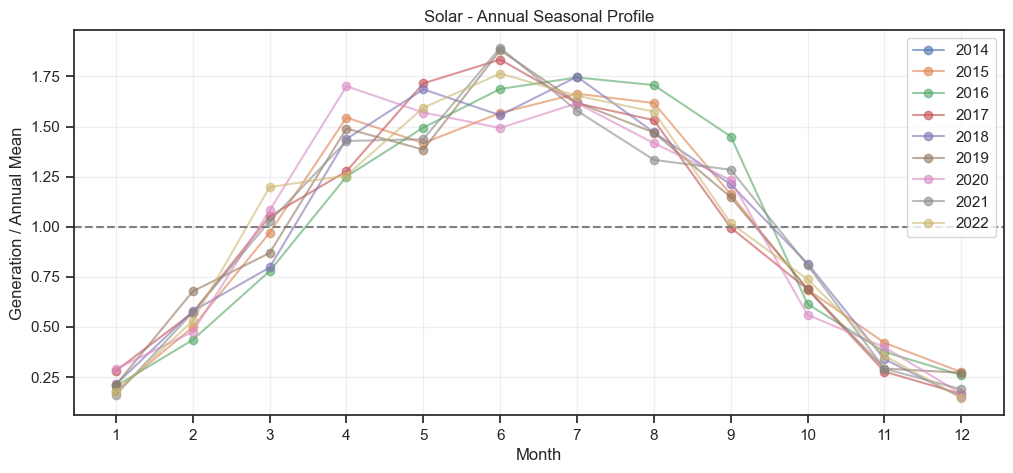

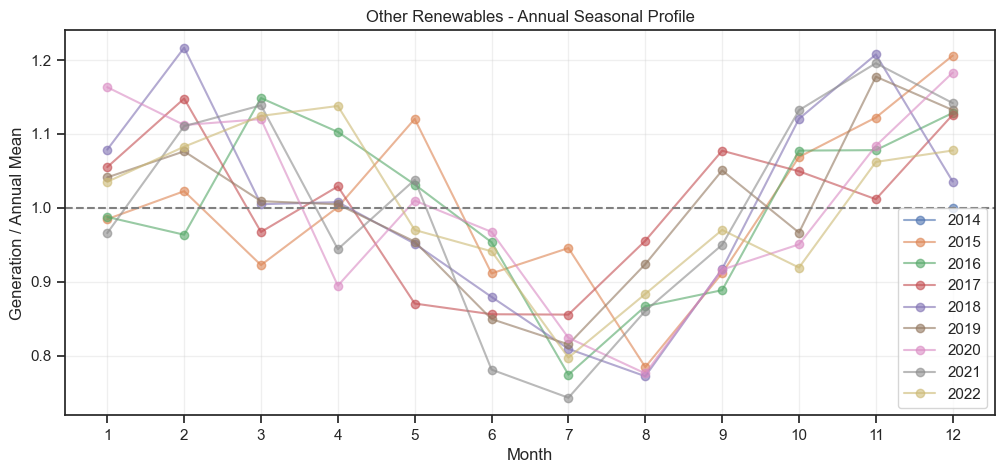

In [58]:
# Aggregate to monthly means
monthly = df_analysis[category_cols].resample("M").mean()
for col in category_cols:
    seasonal = monthly[[col]].copy()

    seasonal["Year"] = seasonal.index.year
    seasonal["Month"] = seasonal.index.month

    # Normalize by each year's mean
    seasonal["Relative_Generation"] = (
        seasonal[col] /
        seasonal.groupby("Year")[col].transform("mean")
    )

    plt.figure(figsize=(12, 5))

    for year, group in seasonal.groupby("Year"):
        plt.plot(
            group["Month"],
            group["Relative_Generation"],
            marker="o",
            alpha=0.6,
            label=str(year)
        )

    plt.axhline(1, linestyle="--", color="gray")

    plt.title(f"{col} - Annual Seasonal Profile")
    plt.xlabel("Month")
    plt.ylabel("Generation / Annual Mean")
    plt.xticks(range(1, 13))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [59]:
import pandas as pd
import numpy as np

# ============================================================
# 1. Prepare hourly time-series data
# ============================================================

df = df_ts_categories.copy()

if "datetime_utc" in df.columns:
    df["datetime_utc"] = pd.to_datetime(
        df["datetime_utc"], utc=True
    )
    df = df.set_index("datetime_utc")
else:
    df.index = pd.to_datetime(df.index, utc=True)

df = df.sort_index()

# Ensure each row represents one hour
if df.index.has_duplicates:
    raise ValueError("Duplicate timestamps found.")

df = df.asfreq("h")

# Select energy generation variables
exclude_cols = ["Hour", "Month", "Season", "Year", "DayOfWeek"]

energy_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

df[energy_cols] = df[energy_cols].apply(
    pd.to_numeric, errors="coerce"
)

# ============================================================
# 2. Calculate lag-1 correlation for each variable
# ============================================================

lag1_results = []

for col in energy_cols:

    current = df[col]
    lag1 = current.shift(1)

    # Pearson correlation using valid observation pairs
    corr = current.corr(lag1)

    # Average error when predicting current value using lag-1
    mae = (current - lag1).abs().mean()

    lag1_results.append({
        "Variable": col,
        "Lag1_Correlation": corr,
        "Lag1_MAE": mae,
        "Missing_Before": current.isna().sum()
    })

lag1_results = pd.DataFrame(lag1_results)

# ============================================================
# 3. Select highly autocorrelated variables
# ============================================================

threshold = 0.99

high_corr_cols = lag1_results.loc[
    lag1_results["Lag1_Correlation"] > threshold,
    "Variable"
].tolist()

print("High lag-1 correlation variables:")
print(high_corr_cols)

# ============================================================
# 4. Impute missing values using previous hour
# ============================================================

df_imputed = df.copy()

for col in high_corr_cols:

    # Only use actual observed values from the previous hour
    previous_hour = df[col].shift(1)

    df_imputed[col] = df[col].fillna(previous_hour)

# ============================================================
# 5. Compare missing values before and after
# ============================================================

lag1_results["Missing_After"] = [
    df_imputed[col].isna().sum()
    for col in lag1_results["Variable"]
]

lag1_results["Values_Imputed"] = (
    lag1_results["Missing_Before"]
    - lag1_results["Missing_After"]
)

lag1_results["Method"] = np.where(
    lag1_results["Lag1_Correlation"] > threshold,
    "Lag-1 Imputation",
    "Not Imputed"
)

print("\nLag-1 Imputation Summary:")
print(lag1_results.round(4))

print("\nTotal missing values before:",
      df[energy_cols].isna().sum().sum())

print("Total missing values after:",
      df_imputed[energy_cols].isna().sum().sum())

High lag-1 correlation variables:
['Nuclear', 'Other Renewables', 'Wind']

Lag-1 Imputation Summary:
           Variable  Lag1_Correlation  Lag1_MAE  Missing_Before  \
0           Nuclear            0.9980   28.2517               0   
1  Other Renewables            0.9907    0.3875               0   
2             Solar            0.9564  481.5719               0   
3           Thermal            0.9847  207.6003               0   
4             Water            0.9018  120.8759               0   
5              Wind            0.9933  384.5111               0   

   Missing_After  Values_Imputed            Method  
0              0               0  Lag-1 Imputation  
1              0               0  Lag-1 Imputation  
2              0               0       Not Imputed  
3              0               0       Not Imputed  
4              0               0       Not Imputed  
5              0               0  Lag-1 Imputation  

Total missing values before: 0
Total missing values after

# Part 3 — Regression-based imputation for remaining energy categories

**Existing cells above are unchanged.** This extends the existing `df`, `df_imputed`, `energy_cols`, and `high_corr_cols` objects. The high-autocorrelation categories continue to use the original lag-1 rule. Categories that do not pass the threshold are compared using **OLS and Ridge** across two feature sets, plus **naive lag-1**. All feature selection and Ridge tuning take place without using future validation/test target values.

**Critical diagnostic:** The prior notebook reports **zero missing category-level values**. In cell 5, `groupby(...).sum()` may map all-missing groups to zero. This new section does not silently reinterpret those zeros as missing values, because legitimate zero generation exists. Check the raw CSV before interpreting any imputation count. The CSV files referenced at the beginning of this notebook must be present in your Jupyter environment.

In [ ]:
# Part 3 / Step 0: Confirm category-level missingness and select model targets.
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

original_model_data = df[energy_cols].copy().sort_index()
regression_targets = [c for c in energy_cols if c not in high_corr_cols]
print("High-correlation (existing lag-1 method):", high_corr_cols)
print("Regression candidate targets:", regression_targets)
print("Category-level missing values BEFORE modeling:")
print(original_model_data.isna().sum().to_string())
if original_model_data.isna().sum().sum() == 0:
    print("WARNING: Category-level data contain no NaNs. Models can be evaluated on known values, "
          "but no actual missing values can be imputed. Check category aggregation of original data.")

# Diagnostic only: inspect all-missing constituent observations in the ORIGINAL (renamed) data.
# This does not alter your original aggregation or imputation code.
if 'df_time' in globals() and 'category_map' in globals():
    for category in energy_cols:
        parts = [c for c in df_time.columns if category_map.get(c) == category]
        if parts:
            all_missing = df_time[parts].isna().all(axis=1).sum()
            any_missing = df_time[parts].isna().any(axis=1).sum()
            print(f"{category}: original constituent rows with ANY missing={any_missing}, "
                  f"ALL missing={all_missing}")


## Step 1 — Construct the candidate feature sets

- **Own-lag + time:** target lag 1, 24, and 168 hours; hour/day-of-year/month cyclic features.
- **Own-lag + time + correlated variables:** add up to three other *contemporaneous* energy categories selected by absolute **training-only** correlation with the target.
- **Benchmark:** naive lag-1 value.

To avoid the current missing target leaking into predictors, lags use only previous observed target values. Same-time predictors are permitted only when actually observed, and should be checked for deterministic target-derived definitions. Cyclical time features are deterministic and do not leak target information.

In [ ]:
# Part 3 / Step 1: Feature construction.
# UTC clock-time is used because that is your current index; convert it first if local time matters.
def make_features(raw, target, selected_external=None):
    idx = raw.index
    hour = idx.hour.to_numpy()
    day_of_year = idx.dayofyear.to_numpy()
    month = idx.month.to_numpy()
    features = pd.DataFrame(index=idx)
    for lag in [1, 24, 168]:
        features[f"{target}_lag{lag}"] = raw[target].shift(lag)
    features["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    features["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    features["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    features["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    features["year_sin"] = np.sin(2 * np.pi * (day_of_year - 1) / 365.25)
    features["year_cos"] = np.cos(2 * np.pi * (day_of_year - 1) / 365.25)
    for c in (selected_external or []):
        features[f"contemporaneous_{c}"] = raw[c]
    return features

# Strictly time-ordered chronological partitions.
n = len(original_model_data)
train_end = int(0.70 * n)
val_end = int(0.85 * n)
train_idx = original_model_data.index[:train_end]
val_idx = original_model_data.index[train_end:val_end]
test_idx = original_model_data.index[val_end:]
print("Train:", train_idx.min(), "to", train_idx.max())
print("Validation:", val_idx.min(), "to", val_idx.max())
print("Test:", test_idx.min(), "to", test_idx.max())

def select_contemporaneous_features(raw, target, train_index, top_k=3):
    # Select on training observations only. Exclude the target itself.
    other = [c for c in raw.columns if c != target]
    correlations = raw.loc[train_index, other].corrwith(raw.loc[train_index, target])
    correlations = correlations.dropna().abs().sort_values(ascending=False)
    return correlations.head(top_k).index.tolist()


## Step 2 — Train OLS and Ridge; select on validation only

Each regression is fitted on rows where **the target and every chosen predictor are observed**. OLS and Ridge are compared on exactly the same valid validation observations as lag-1 for that feature set. For selection across feature sets, candidates are scored on a common validation subset when possible; candidate coverage is also reported. The baseline is retained when a model does not improve validation MAE.

Because your dataset may include runs of consecutive missing hours, complete-case model predictions can be unavailable for some gaps; the final stage provides an explicit fallback and leaves unresolved gaps as NaN.

In [ ]:
# Part 3 / Step 2: Model fitting, validation, and held-out testing.
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0, 1000.0]


def create_estimator(model_name, alpha=None):
    if model_name == "OLS":
        return Pipeline([("scale", StandardScaler()),
                         ("regression", LinearRegression())])
    return Pipeline([("scale", StandardScaler()),
                     ("regression", Ridge(alpha=alpha))])


def score_predictions(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }


fitted_candidates = {}  # (target, feature_set, model, alpha) -> training fit
records = []
feature_sets = {}

for target in regression_targets:
    externals = select_contemporaneous_features(original_model_data, target, train_idx)
    feature_sets[target] = {
        "own_lags_time": [],
        "own_lags_time_plus_others": externals
    }
    # Evaluate two feature sets, each with OLS and Ridge.
    for feature_set_name, extra_cols in feature_sets[target].items():
        X = make_features(original_model_data, target, extra_cols)
        y = original_model_data[target]
        valid = X.notna().all(axis=1) & y.notna()
        train_rows = valid & X.index.isin(train_idx)
        val_rows = valid & X.index.isin(val_idx)
        if train_rows.sum() < 100 or val_rows.sum() < 30:
            print(f"SKIP {target} / {feature_set_name}: insufficient complete rows")
            continue
        # Evaluate the same timestamps for the lag-1 benchmark.
        benchmark = original_model_data[target].shift(1)
        benchmark_rows = val_rows & benchmark.notna()
        if benchmark_rows.sum() < 30:
            continue
        eval_X = X.loc[benchmark_rows]
        eval_y = y.loc[benchmark_rows]
        benchmark_score = score_predictions(eval_y, benchmark.loc[benchmark_rows])
        records.append(dict(Target=target, Feature_Set=feature_set_name,
                            Model="Naive lag-1", Alpha=np.nan,
                            N_Train=int(train_rows.sum()), N_Validation=int(benchmark_rows.sum()),
                            **benchmark_score))

        for model_name, alphas in [("OLS", [None]), ("Ridge", RIDGE_ALPHAS)]:
            for alpha in alphas:
                estimator = create_estimator(model_name, alpha)
                estimator.fit(X.loc[train_rows], y.loc[train_rows])
                predictions = estimator.predict(eval_X)
                scores = score_predictions(eval_y, predictions)
                records.append(dict(Target=target, Feature_Set=feature_set_name,
                                    Model=model_name, Alpha=alpha if alpha is not None else np.nan,
                                    N_Train=int(train_rows.sum()), N_Validation=int(benchmark_rows.sum()),
                                    **scores))
                fitted_candidates[(target, feature_set_name, model_name, alpha)] = estimator

validation_table = pd.DataFrame(records)
print("\n=== Validation Results ===")
print(validation_table.round(3).to_string(index=False))

# Choose a method per target using validation MAE, with a strict naive fallback.
# Cross-feature-set rankings use a COMMON validation set to ensure comparability.
selected_models = {}
selection_rows = []
for target in regression_targets:
    choices = validation_table[validation_table.Target == target]
    if choices.empty:
        selected_models[target] = ("Naive lag-1", None, None)
        continue
    # Determine common evaluation rows for all available feature sets.
    usable_sets = [name for name in feature_sets[target]
                   if not choices[choices.Feature_Set == name].empty]
    X_by_set = {name: make_features(original_model_data, target, feature_sets[target][name])
                for name in usable_sets}
    common = original_model_data.index.isin(val_idx) & original_model_data[target].notna()
    common &= original_model_data[target].shift(1).notna()
    for X in X_by_set.values():
        common &= X.notna().all(axis=1)
    if common.sum() < 30:
        # Cannot compare feature sets fairly; use conservative baseline.
        selected_models[target] = ("Naive lag-1", None, None)
        selection_rows.append({"Target": target, "Method": "Naive lag-1",
                               "Feature_Set": None, "Alpha": np.nan,
                               "Validation_MAE": np.nan,
                               "Note": "Insufficient common validation rows"})
        continue
    y_val = original_model_data.loc[common, target]
    lag1_val = original_model_data[target].shift(1).loc[common]
    best_score = mean_absolute_error(y_val, lag1_val)
    best = ("Naive lag-1", None, None)
    for name, X in X_by_set.items():
        for model_name, alphas in [("OLS", [None]), ("Ridge", RIDGE_ALPHAS)]:
            for alpha in alphas:
                estimator = fitted_candidates[(target, name, model_name, alpha)]
                pred = estimator.predict(X.loc[common])
                mae = mean_absolute_error(y_val, pred)
                if mae < best_score:
                    best_score = mae
                    best = (model_name, name, alpha)
    selected_models[target] = best
    selection_rows.append({"Target": target, "Method": best[0],
                           "Feature_Set": best[1], "Alpha": best[2],
                           "Validation_MAE": best_score, "Note": "Common validation timestamps"})

selection_table = pd.DataFrame(selection_rows)
print("\n=== Method Selected per Target ===")
print(selection_table.to_string(index=False))


In [ ]:
# Part 3 / Step 3: Evaluate selected methods on held-out test observations.
# Refit regression on train+validation only, then evaluate on test (no test targets used in fitting).
test_records = []
for target in regression_targets:
    model_name, feature_name, alpha = selected_models[target]
    if model_name == "Naive lag-1":
        X = make_features(original_model_data, target)
    else:
        X = make_features(original_model_data, target, feature_sets[target][feature_name])
    y = original_model_data[target]
    lag1 = original_model_data[target].shift(1)
    valid = X.notna().all(axis=1) & y.notna() & lag1.notna()
    test_rows = valid & X.index.isin(test_idx)
    fit_rows = valid & (X.index.isin(train_idx) | X.index.isin(val_idx))
    if test_rows.sum() == 0:
        print(f"No eligible held-out test rows for {target}")
        continue
    if model_name == "Naive lag-1":
        pred = lag1.loc[test_rows].to_numpy()
    else:
        estimator = create_estimator(model_name, alpha)
        estimator.fit(X.loc[fit_rows], y.loc[fit_rows])
        pred = estimator.predict(X.loc[test_rows])
    metrics = score_predictions(y.loc[test_rows], pred)
    test_records.append({"Target": target, "Selected_Method": model_name,
                         "Feature_Set": feature_name, "N_Test": int(test_rows.sum()),
                         **metrics})

test_table = pd.DataFrame(test_records)
print("\n=== Held-out Test Performance ===")
print(test_table.round(3).to_string(index=False))


## Step 4 — Apply each selected method to genuine missing target values

Regressions are refitted on **all complete observed rows** after the held-out assessment, then applied to missing target observations with available features. If a regression cannot predict a row because predictors are missing, use that target's **original observed lag-1** when available. This step leaves longer or unsupported missing runs unresolved; it never claims an imputation happened when no NaNs exist.

In [ ]:
# Part 3 / Step 4: Final imputation; preserve the earlier lag-1 choices.
# Start with the output of your existing code without changing it.
df_imputed_final = df_imputed.copy()
fill_log = []

for target in regression_targets:
    model_name, feature_name, alpha = selected_models[target]
    y = original_model_data[target]
    missing = y.isna()
    if not missing.any():
        continue

    if model_name != "Naive lag-1":
        X = make_features(original_model_data, target, feature_sets[target][feature_name])
        fit_rows = X.notna().all(axis=1) & y.notna()
        predict_rows = X.notna().all(axis=1) & missing
        if fit_rows.sum() >= 100 and predict_rows.any():
            model = create_estimator(model_name, alpha)
            model.fit(X.loc[fit_rows], y.loc[fit_rows])
            estimated = pd.Series(model.predict(X.loc[predict_rows]),
                                  index=X.index[predict_rows])
            df_imputed_final.loc[estimated.index, target] = estimated
            for date, value in estimated.items():
                fill_log.append({"Timestamp": date, "Target": target,
                                 "Method": model_name,
                                 "Feature_Set": feature_name, "Value": value})

    # Explicit naive lag-1 fallback, using ORIGINAL observations only.
    remaining = y.isna() & df_imputed_final[target].isna()
    naive_lag1 = y.shift(1)
    use_lag1 = remaining & naive_lag1.notna()
    df_imputed_final.loc[use_lag1, target] = naive_lag1.loc[use_lag1]
    for date, value in naive_lag1.loc[use_lag1].items():
        fill_log.append({"Timestamp": date, "Target": target,
                         "Method": "Naive lag-1 (fallback)",
                         "Feature_Set": None, "Value": value})

# Confirm original observed values have not been changed.
for target in energy_cols:
    observed = original_model_data[target].notna()
    assert df_imputed_final.loc[observed, target].equals(original_model_data.loc[observed, target])

imputation_audit = pd.DataFrame(fill_log)
final_summary = pd.DataFrame({
    "Missing_Before": original_model_data.isna().sum(),
    "Missing_After": df_imputed_final[energy_cols].isna().sum()
})
final_summary["Imputed"] = final_summary.Missing_Before - final_summary.Missing_After
print("\n=== Final Imputation Summary ===")
print(final_summary.to_string())
print("\nActual regression-stage imputed values:", len(imputation_audit))

# Restore original time/category structure: result is df_imputed_final.
# Optionally save after checking your diagnostics:
# df_imputed_final.to_csv("electricity_imputed_final.csv", index_label="datetime_utc")
# validation_table.to_csv("ols_ridge_validation.csv", index=False)
# test_table.to_csv("ols_ridge_test.csv", index=False)
# imputation_audit.to_csv("regression_imputation_audit.csv", index=False)
